# MINI PROJECT: MUSIC RECOMMENDATION SYSTEM USING MACHINE LEARNING

In [1]:
# Display the project team and reviewer; these do not affect the model.
dev_by = "Ashish Umrao, Abhijeet Kumar, and Aryan Singh"
checked_by = "वैशाली इंगळे"
print("Developed by: " + dev_by + "\n" + "Checked by: " + checked_by)

Developed by: Ashish Umrao, Abhijeet Kumar, and Aryan Singh
Checked by: वैशाली इंगळे


## 1. PROBLEM DEFINITION

Music streaming apps contain millions of songs, so a listener cannot search through all of them manually.
A **recommendation system** helps the listener by suggesting new songs that are similar to a song they already like.

**Objective:** Build a **content-based music recommendation system** that, given one song, recommends the
**10 most similar songs** using only the song's audio features (danceability, energy, loudness, acousticness, tempo, etc.).

**Approach:** The project uses KNN for content-based recommendations and genre classification.

- Every song is represented as a point in feature space.
- Songs that are *close* to each other in this space *sound* similar.
- **Recommendation:** `NearestNeighbors` retrieves the nearest songs by audio-feature distance. It is a search method, not a classifier or a clustering algorithm.
- **Genre classification:** `KNeighborsClassifier` predicts genre from labeled songs. The results also compare this classifier with a Decision Tree and Gaussian Naïve Bayes using the same train/test split and features.
- **Evaluation:** classification uses Accuracy, Precision, Recall, F1-Score and Confusion Matrix; recommendation quality uses **Precision@10**, the fraction of the 10 recommendations sharing the input song's genre.
- **Optimization:** Cross Validation and `GridSearchCV` tune KNN; the Decision Tree and Gaussian Naïve Bayes comparison uses their stated baseline settings, so it compares tested configurations rather than equally tuned model families.

### PEAS Representation of the Recommendation Agent

| PEAS Component | Music Recommendation System |
|---|---|
| **Performance Measure** | Accuracy, Precision, Recall, F1-Score of genre prediction; Precision@10 of recommendations (same-genre songs) |
| **Environment** | Song catalogue (Spotify Tracks Dataset) and a user selecting a song in the notebook or desktop app |
| **Actuators** | Displaying the top-10 recommended songs and model evaluation results |
| **Sensors** | The song name entered by the user and that song's audio features from the dataset |

## 2. DATASET COLLECTION

**Dataset:** Spotify Tracks Dataset (114,000 songs, 114 genres, 1,000 songs per genre).

- Hugging Face: https://huggingface.co/datasets/maharshipandya/spotify-tracks-dataset
- Kaggle: search "Spotify Tracks Dataset" by Maharshi Pandya (same `dataset.csv` file)

Download `dataset.csv` and keep it in the same folder as this notebook.

#### IMPORTING LIBRARIES

In [2]:
# pandas: tables; NumPy: arrays; Matplotlib and Seaborn: graphs.
# LabelEncoder converts text categories into numbers.
# MinMaxScaler puts all features in the range 0 to 1.
# KNeighborsClassifier predicts genre; NearestNeighbors finds similar songs.
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import LabelEncoder
from sklearn.preprocessing import MinMaxScaler
from sklearn.model_selection import train_test_split
from sklearn.model_selection import cross_val_score, GridSearchCV

from sklearn.neighbors import KNeighborsClassifier
from sklearn.neighbors import NearestNeighbors

from sklearn.metrics import accuracy_score,precision_score,recall_score,f1_score,classification_report,confusion_matrix

#### LOADING DATASET

In [3]:
df = pd.read_csv("dataset.csv")

## Printing number of samples and features in our dataset.
print("Number of samples: ", df.shape[0])
print("Number of features: ", df.shape[1])

Number of samples:  114000
Number of features:  21


In [4]:
## PRINTING TOP 5 SAMPLES OF OUR DATASET.
df.head(5)

,Unnamed: 0,track_id,artists,album_name,track_name,popularity,duration_ms,explicit,danceability,energy,...,loudness,mode,speechiness,acousticness,instrumentalness,liveness,valence,tempo,time_signature,track_genre
0,0,5SuOikwiRyPMVoIQDJUgSV,Gen Hoshino,Comedy,Comedy,73,230666,False,0.676,0.4610,...,-6.746,0,0.1430,0.0322,0.000001,0.3580,0.715,87.917,4,acoustic
1,1,4qPNDBW1i3p13qLCt0Ki3A,Ben Woodward,Ghost (Acoustic),Ghost - Acoustic,55,149610,False,0.420,0.1660,...,-17.235,1,0.0763,0.9240,0.000006,0.1010,0.267,77.489,4,acoustic
2,2,1iJBSr7s7jYXzM8EGcbK5b,Ingrid Michaelson;ZAYN,To Begin Again,To Begin Again,57,210826,False,0.438,0.3590,...,-9.734,1,0.0557,0.2100,0.000000,0.1170,0.120,76.332,4,acoustic
3,3,6lfxq3CG4xtTiEg7opyCyx,Kina Grannis,Crazy Rich Asians (Original Motion Picture Sou...,Can't Help Falling In Love,71,201933,False,0.266,0.0596,...,-18.515,1,0.0363,0.9050,0.000071,0.1320,0.143,181.740,3,acoustic
4,4,5vjLSffimiIP26QG5WcN2K,Chord Overstreet,Hold On,Hold On,82,198853,False,0.618,0.4430,...,-9.681,1,0.0526,0.4690,0.000000,0.0829,0.167,119.949,4,acoustic


In [5]:
## Printing feature name alongwith its total values present and its data type
for col in df.columns:
    print(f'feature Name = "{col}",' , f'Total Values Present = {df[col].count()},',  f'Data Type = {df[col].dtype}')

feature Name = "Unnamed: 0", Total Values Present = 114000, Data Type = int64
feature Name = "track_id", Total Values Present = 114000, Data Type = str
feature Name = "artists", Total Values Present = 113999, Data Type = str
feature Name = "album_name", Total Values Present = 113999, Data Type = str
feature Name = "track_name", Total Values Present = 113999, Data Type = str
feature Name = "popularity", Total Values Present = 114000, Data Type = int64
feature Name = "duration_ms", Total Values Present = 114000, Data Type = int64
feature Name = "explicit", Total Values Present = 114000, Data Type = bool
feature Name = "danceability", Total Values Present = 114000, Data Type = float64
feature Name = "energy", Total Values Present = 114000, Data Type = float64
feature Name = "key", Total Values Present = 114000, Data Type = int64
feature Name = "loudness", Total Values Present = 114000, Data Type = float64
feature Name = "mode", Total Values Present = 114000, Data Type = int64
feature Name

In [6]:
## Number of genres present in the dataset
print("Number of genres:", df["track_genre"].nunique())
print("\nSongs per genre (first 10):")
print(df["track_genre"].value_counts().head(10))

Number of genres: 114

Songs per genre (first 10):
track_genre
acoustic       1000
afrobeat       1000
alt-rock       1000
alternative    1000
ambient        1000
anime          1000
black-metal    1000
bluegrass      1000
blues          1000
brazil         1000
Name: count, dtype: int64


## 3. DATA PREPROCESSING

#### DATA CLEANING

In [7]:
## "Unnamed: 0" is only a row number, so it is not useful. Dropping this column.
df.drop(columns=["Unnamed: 0"], inplace=True)

#### Detect Missing Values

In [8]:
for col in df.columns:
    print(f"Column Name      : {col}")
    print(f"Missing Values   : {df[col].isnull().sum()}")
    print("-" * 35)

Column Name      : track_id
Missing Values   : 0
-----------------------------------
Column Name      : artists
Missing Values   : 1
-----------------------------------
Column Name      : album_name
Missing Values   : 1
-----------------------------------
Column Name      : track_name
Missing Values   : 1
-----------------------------------
Column Name      : popularity
Missing Values   : 0
-----------------------------------
Column Name      : duration_ms
Missing Values   : 0
-----------------------------------
Column Name      : explicit
Missing Values   : 0
-----------------------------------
Column Name      : danceability
Missing Values   : 0
-----------------------------------
Column Name      : energy
Missing Values   : 0
-----------------------------------
Column Name      : key
Missing Values   : 0
-----------------------------------
Column Name      : loudness
Missing Values   : 0
-----------------------------------
Column Name      : mode
Missing Values   : 0
---------------

#### HANDLING MISSING VALUES

In [9]:
# Only one song has missing artist / album / track name.
# A song without a name cannot be recommended, so that row is removed.
df.dropna(inplace=True)

print("Missing values after handling:", df.isnull().sum().sum())
print("Number of samples:", df.shape[0])

Missing values after handling: 0
Number of samples: 113999


#### SELECTING GENRES

114 genres is too many, and many of them overlap (rock, alt-rock, hard-rock, ...).
We select **7 clearly different genres** so that the results are easy to understand and the model trains quickly.

In [10]:
selected_genres = ["classical", "hip-hop", "heavy-metal", "edm", "jazz", "country", "pop"]

df = df[df["track_genre"].isin(selected_genres)].reset_index(drop=True)

print("Number of samples: ", df.shape[0])
print(df["track_genre"].value_counts())

Number of samples:  7000
track_genre
classical      1000
country        1000
edm            1000
heavy-metal    1000
hip-hop        1000
jazz           1000
pop            1000
Name: count, dtype: int64


#### HANDLING DUPLICATE SONGS

In [11]:
# 1. The same track_id can appear under more than one genre.
# 2. The same song (same name and artist) can appear on different albums with a different track_id.
# Keeping duplicates would make the system recommend the same song again, so we keep only the first copy.
print("Duplicate track_id:", df.duplicated(subset="track_id").sum())
df = df.drop_duplicates(subset="track_id")

print("Duplicate songs (same name and artist):", df.duplicated(subset=["track_name", "artists"]).sum())
df = df.drop_duplicates(subset=["track_name", "artists"]).reset_index(drop=True)

print("\nNumber of samples after removing duplicates:", df.shape[0])

Duplicate track_id: 255
Duplicate songs (same name and artist): 1820

Number of samples after removing duplicates: 4925


#### STATISTICAL ANALYSIS

In [12]:
df.describe()

,popularity,duration_ms,danceability,energy,key,loudness,mode,speechiness,acousticness,instrumentalness,liveness,valence,tempo,time_signature
count,4925.000000,4.925000e+03,4925.000000,4925.000000,4925.000000,4925.000000,4925.000000,4925.000000,4925.000000,4925.000000,4925.000000,4925.000000,4925.000000,4925.000000
mean,34.433096,2.253500e+05,0.544904,0.604030,5.338883,-8.995889,0.625584,0.074575,0.352922,0.138003,0.197743,0.456741,119.460469,3.890355
std,28.617676,1.153140e+05,0.173157,0.280835,3.534310,6.516121,0.484021,0.070954,0.368777,0.301409,0.168785,0.227343,29.854606,0.446757
min,0.000000,1.745300e+04,0.000000,0.000756,0.000000,-41.531000,0.000000,0.000000,0.000002,0.000000,0.021100,0.000000,0.000000,0.000000
25%,1.000000,1.745080e+05,0.425000,0.417000,2.000000,-10.229000,0.000000,0.036000,0.016000,0.000000,0.097800,0.279000,95.983000,4.000000
50%,30.000000,2.105330e+05,0.548000,0.660000,5.000000,-6.695000,1.000000,0.047900,0.184000,0.000021,0.129000,0.448000,119.800000,4.000000
75%,63.000000,2.546930e+05,0.676000,0.835000,9.000000,-4.872000,1.000000,0.079900,0.713000,0.012900,0.245000,0.622000,139.933000,4.000000
max,100.000000,2.646866e+06,0.964000,0.998000,11.000000,0.366000,1.000000,0.905000,0.996000,0.984000,0.986000,0.979000,214.016000,5.000000


#### DATA VISUALISATION

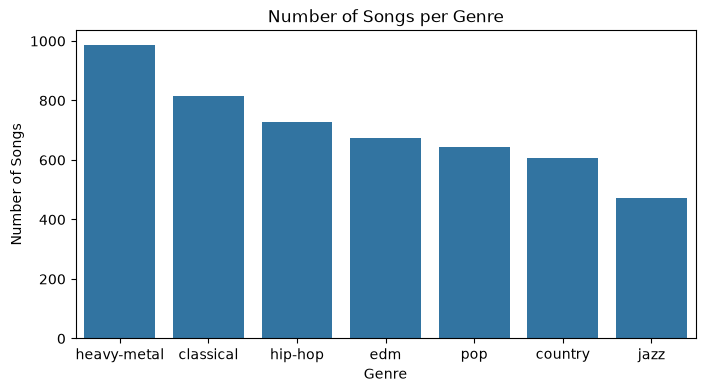

In [13]:
# Number of songs in each selected genre after cleaning.
plt.figure(figsize=(8, 4))
sns.countplot(data=df, x="track_genre", order=df["track_genre"].value_counts().index)
plt.title("Number of Songs per Genre")
plt.xlabel("Genre")
plt.ylabel("Number of Songs")
plt.show()

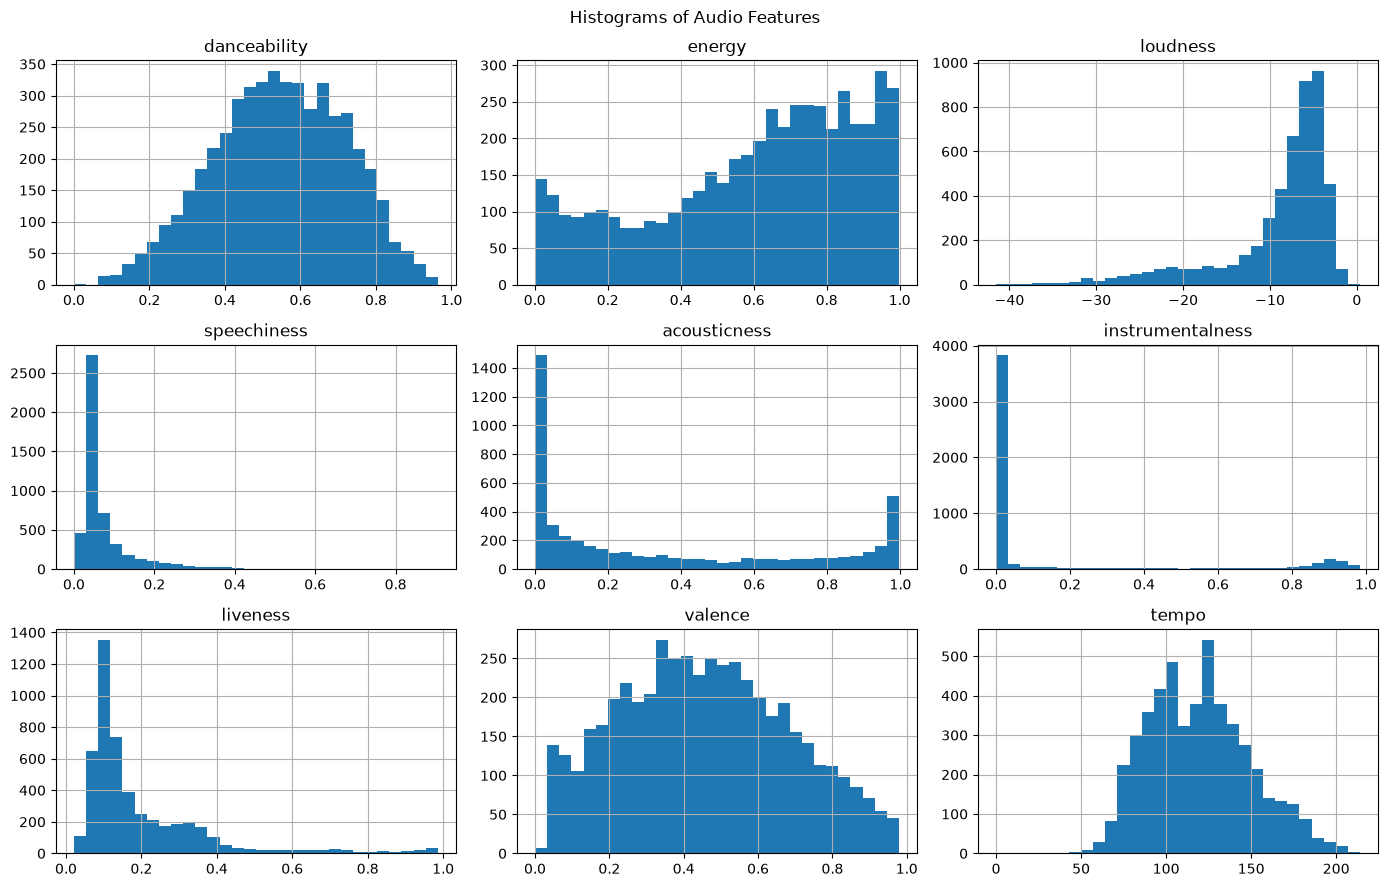

In [14]:
# Histograms show the distribution of each audio feature.
audio_features = ["danceability", "energy", "loudness", "speechiness", "acousticness",
                  "instrumentalness", "liveness", "valence", "tempo"]

df[audio_features].hist(figsize=(14, 9), bins=30)
plt.suptitle("Histograms of Audio Features")
plt.tight_layout()
plt.show()

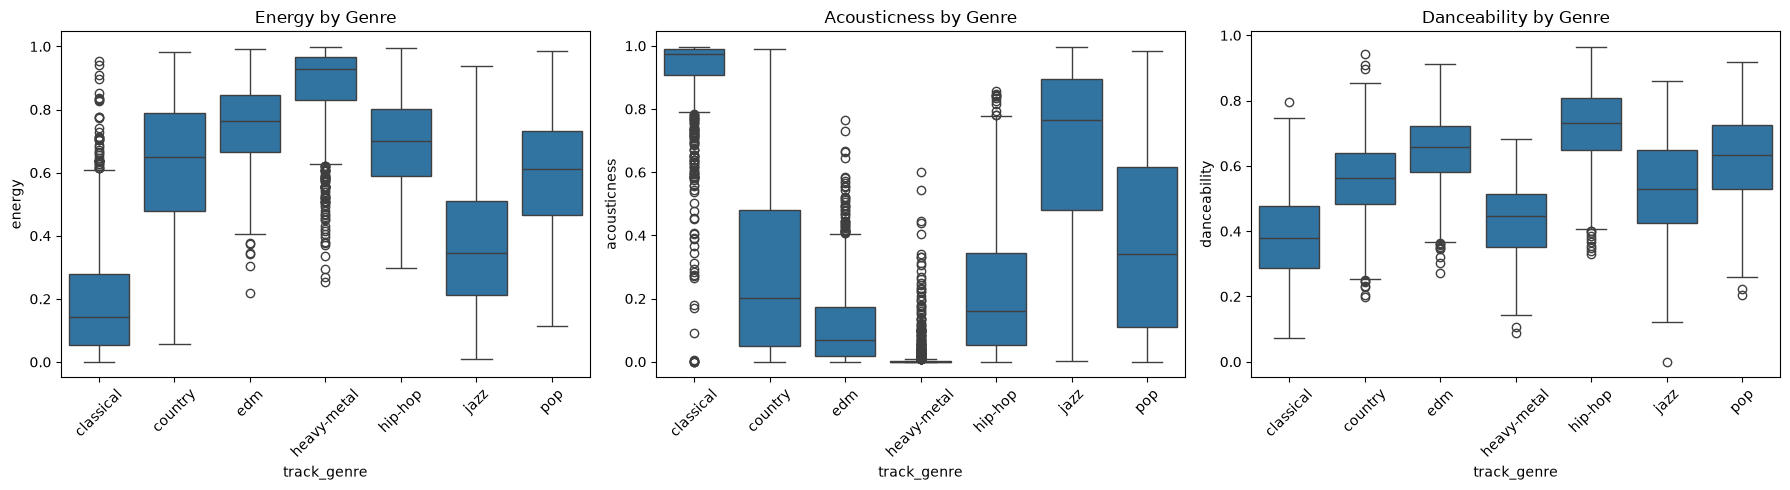

In [15]:
# Boxplots show how a feature changes from genre to genre and also show outliers.
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

sns.boxplot(data=df, x="track_genre", y="energy", ax=axes[0])
axes[0].set_title("Energy by Genre")

sns.boxplot(data=df, x="track_genre", y="acousticness", ax=axes[1])
axes[1].set_title("Acousticness by Genre")

sns.boxplot(data=df, x="track_genre", y="danceability", ax=axes[2])
axes[2].set_title("Danceability by Genre")

for ax in axes:
    ax.tick_params(axis="x", rotation=45)

plt.tight_layout()
plt.show()

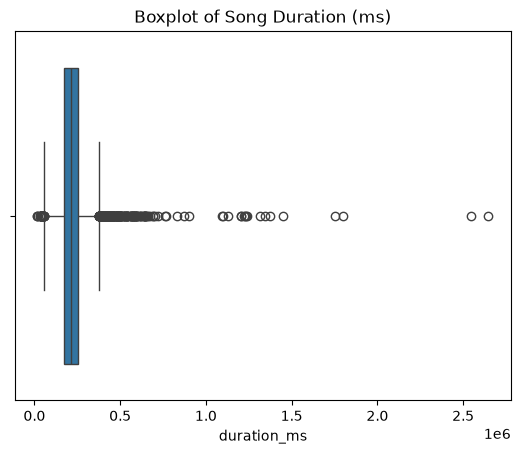

In [16]:
# Boxplot of duration shows outliers (very long songs).
sns.boxplot(x=df["duration_ms"])
plt.title("Boxplot of Song Duration (ms)")
plt.show()

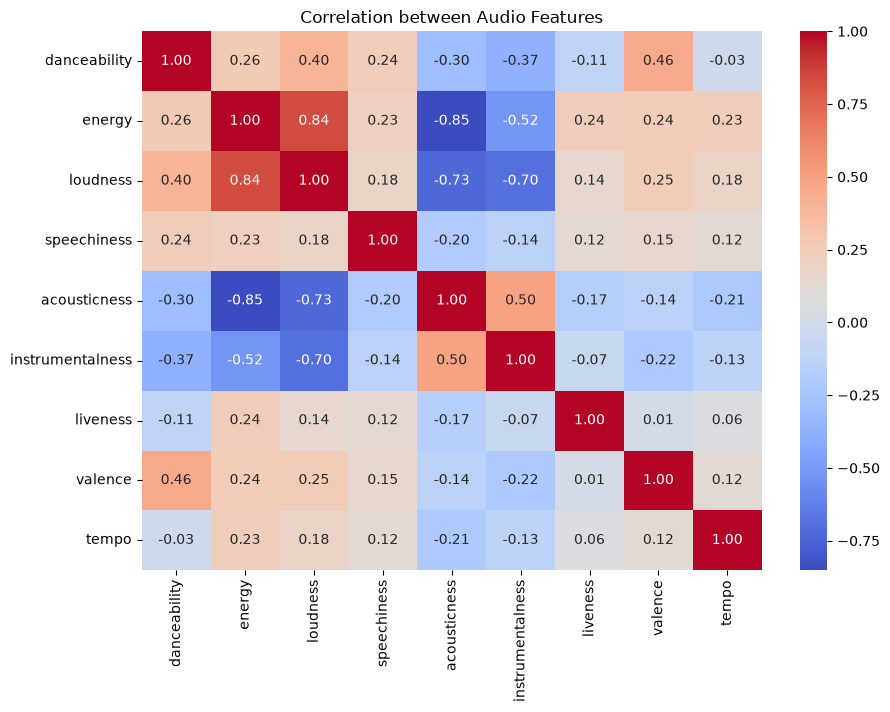

In [17]:
# Correlation heatmap shows which audio features are related to each other.
plt.figure(figsize=(10, 7))
sns.heatmap(df[audio_features].corr(), annot=True, fmt=".2f", cmap="coolwarm")
plt.title("Correlation between Audio Features")
plt.show()

#### ENCODING

In [18]:
encoder = LabelEncoder()

# "explicit" is True / False, so it is converted into 1 / 0.
df["explicit"] = encoder.fit_transform(df["explicit"])

# Target column: genre names are converted into numbers.
genre_encoder = LabelEncoder()
df["genre_label"] = genre_encoder.fit_transform(df["track_genre"])

print("Genre classes:", list(genre_encoder.classes_))
df[["track_name", "explicit", "track_genre", "genre_label"]].head()

Genre classes: ['classical', 'country', 'edm', 'heavy-metal', 'hip-hop', 'jazz', 'pop']


,track_name,explicit,track_genre,genre_label
0,Zara Zara,0,classical,0
1,Kajra Re,0,classical,0
2,Zara Zara - Lofi,0,classical,0
3,Vaseegara,0,classical,0
4,Zara Zara - LoFi Chill,0,classical,0


#### DEPENDENT AND INDEPENDENT FEATURES

In [19]:
# Only the audio features describe how a song sounds, so only these are used.
# track_id, artists, album_name, track_name are text and are only used to display recommendations.
# popularity is not used because it describes how famous a song is, not how it sounds.
# key and time_signature are not used because they gave lower accuracy during testing.
feature_cols = ["danceability", "energy", "loudness", "speechiness", "acousticness",
                "instrumentalness", "liveness", "valence", "tempo",
                "duration_ms", "mode", "explicit"]

X = df[feature_cols]
y = df["genre_label"]

print("Number of input features:", X.shape[1])

Number of input features: 12


#### TRAIN TEST SPLIT

In [20]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

## Printing number of samples and features in our TRAINING and TESTING dataset.
print("Number of samples in training dataset: ", X_train.shape[0])
print("Number of features in training dataset: ", X_train.shape[1])
print("Number of samples in testing dataset: ", X_test.shape[0])
print("Number of features in testing dataset: ", X_test.shape[1])

Number of samples in training dataset:  3940
Number of features in training dataset:  12
Number of samples in testing dataset:  985
Number of features in testing dataset:  12


#### FEATURE SCALING

In [21]:
# KNN uses distance, so a feature with large values (duration_ms, tempo) would dominate.
# MinMaxScaler brings every feature into the range 0 to 1.
# The scaler is fitted only on training data so that test data stays unseen.
scaler = MinMaxScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

pd.DataFrame(X_train_scaled, columns=feature_cols).head()

,danceability,energy,loudness,speechiness,acousticness,instrumentalness,liveness,valence,tempo,duration_ms,mode,explicit
0,0.581950,0.897718,0.898871,0.049945,0.004947,0.000002,0.123026,0.719101,0.617178,0.072407,1.0,0.0
1,0.501037,0.490596,0.810480,0.044199,0.822289,0.000111,0.139651,0.252298,0.360445,0.079228,1.0,0.0
2,0.704357,0.587864,0.832674,0.304972,0.141564,0.000006,0.118869,0.496425,0.869108,0.081007,1.0,1.0
3,0.702282,0.551765,0.773280,0.070276,0.394577,0.000000,0.111596,0.711951,0.735856,0.080644,1.0,0.0
4,0.712656,0.855602,0.872407,0.340331,0.062146,0.000655,0.129260,0.736466,1.000000,0.057980,0.0,0.0


## 4. MODEL DEVELOPMENT

#### KNN CLASSIFIER (DEFAULT PARAMETERS)

In [22]:
# Default KNN: K = 5 neighbors, Euclidean distance, all neighbors have equal vote.
knn = KNeighborsClassifier()
knn.fit(X_train_scaled, y_train)
print("KNN training completed")
print("Parameters:", knn.get_params())

KNN training completed
Parameters: {'algorithm': 'auto', 'leaf_size': 30, 'metric': 'minkowski', 'metric_params': None, 'n_jobs': None, 'n_neighbors': 5, 'p': 2, 'weights': 'uniform'}


#### KNN RECOMMENDER (NEAREST NEIGHBORS)

In [23]:
# The recommender uses the same KNN idea without a target column:
# it simply finds the K songs whose audio features are closest to the given song.
all_songs_scaled = scaler.transform(X)

recommender = NearestNeighbors(n_neighbors=11, metric="euclidean")
recommender.fit(all_songs_scaled)

print("Recommender is ready. Songs in catalogue:", all_songs_scaled.shape[0])

Recommender is ready. Songs in catalogue: 4925


In [24]:
def recommend_songs(song_name, model, n_recommendations=10):
    """Return the top-N songs most similar to the given song."""

    # Search the song name (not case sensitive).
    matches = df[df["track_name"].str.lower() == song_name.lower()]

    if matches.empty:
        print(f"'{song_name}' is not present in the dataset.")
        return None

    # If the same name exists more than once, the first song is used.
    song_index = matches.index[0]
    song = df.loc[song_index]

    print(f"Input Song : {song['track_name']}  |  Artist: {song['artists']}  |  Genre: {song['track_genre']}")

    # Find nearest songs (one extra because the closest song is the input song itself).
    distances, indices = model.kneighbors(all_songs_scaled[[song_index]], n_neighbors=n_recommendations + 1)

    result = df.loc[indices[0], ["track_name", "artists", "track_genre"]].copy()
    result["distance"] = distances[0].round(4)

    # Remove the input song from its own recommendations.
    result = result[result.index != song_index].head(n_recommendations)

    return result.reset_index(drop=True)

In [25]:
recommend_songs("Nuvole Bianche", recommender)

Input Song : Nuvole Bianche  |  Artist: Ludovico Einaudi  |  Genre: classical


,track_name,artists,track_genre,distance
0,"Piano Concerto No. 27 in B-Flat Major, K. 595:...",Wolfgang Amadeus Mozart;Wilhelm Kempff;Berline...,classical,0.1136
1,"Nabucco: Va, pensiero, sull'ali dorate - Edit",Giuseppe Verdi;Chicago Symphony Chorus;Chicago...,classical,0.1417
2,"Adagio in F, K.410",Wolfgang Amadeus Mozart;Holliger Wind Ensemble,classical,0.1635
3,"Saul, HWV 53: Dead March",George Frideric Handel;London Early Opera;Brid...,classical,0.1670
4,Una Mattina,Ludovico Einaudi,classical,0.1735
5,"Cello Sonata in C Major, Op. 119: I. Andante g...",Sergei Prokofiev;Miriam K. Smith;Sandra Wright...,classical,0.1834
6,"Piano Concerto No. 23 in A Major, K. 488: II. ...",Wolfgang Amadeus Mozart;Ingrid Haebler;London ...,classical,0.1962
7,Box of Memories,Josh Kramer,classical,0.1996
8,Orfeo Ed Euridice: Dance of the Blessed Spirit...,Christoph Willibald Gluck;Karlheinz Zoeller;Be...,classical,0.2121
9,"Ma mère l'Oye, M. 60: Apothéose: Le jardin fée...",Maurice Ravel;Michael Davis;London Symphony Or...,classical,0.2140


## 5. PERFORMANCE EVALUATION

#### GENRE PREDICTION METRICS

In [26]:
# Predict on testing data
y_pred = knn.predict(X_test_scaled)

# Calculate evaluation metrics
accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred, average="weighted", zero_division=0)
recall = recall_score(y_test, y_pred, average="weighted", zero_division=0)
f1 = f1_score(y_test, y_pred, average="weighted", zero_division=0)

print("Accuracy :", round(accuracy, 4))
print("Precision:", round(precision, 4))
print("Recall   :", round(recall, 4))
print("F1-Score :", round(f1, 4))

Accuracy : 0.5756
Precision: 0.5723
Recall   : 0.5756
F1-Score : 0.5684


In [27]:
print(classification_report(y_test, y_pred, target_names=genre_encoder.classes_))

              precision    recall  f1-score   support

   classical       0.87      0.80      0.83       163
     country       0.39      0.50      0.44       121
         edm       0.41      0.50      0.45       135
 heavy-metal       0.80      0.87      0.83       197
     hip-hop       0.52      0.52      0.52       145
        jazz       0.42      0.37      0.39        95
         pop       0.36      0.19      0.25       129

    accuracy                           0.58       985
   macro avg       0.54      0.54      0.53       985
weighted avg       0.57      0.58      0.57       985



#### CONFUSION MATRIX

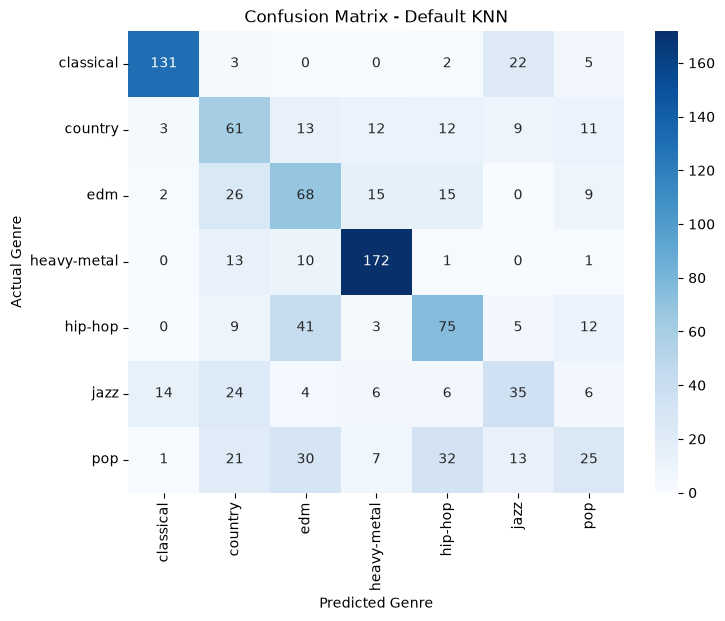

In [28]:
cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=genre_encoder.classes_, yticklabels=genre_encoder.classes_)
plt.title("Confusion Matrix - Default KNN")
plt.xlabel("Predicted Genre")
plt.ylabel("Actual Genre")
plt.show()

#### RECOMMENDATION QUALITY: PRECISION@10

For every song in the **testing set**, we find its 10 nearest songs in the **training set**
and check how many of them have the same genre.

In [29]:
def precision_at_k(model, k=10):
    """Average fraction of the k recommended songs that share the input song's genre."""

    model.fit(X_train_scaled)
    distances, indices = model.kneighbors(X_test_scaled, n_neighbors=k)

    train_genres = y_train.values
    test_genres = y_test.values

    # For each test song: count neighbours with the same genre, divide by k.
    hits = (train_genres[indices] == test_genres[:, None]).sum(axis=1)
    return (hits / k).mean()


default_p_at_10 = precision_at_k(NearestNeighbors(metric="euclidean"), k=10)
print("Precision@10 (default recommender):", round(default_p_at_10, 4))

Precision@10 (default recommender): 0.4936


#### CHOOSING THE VALUE OF K

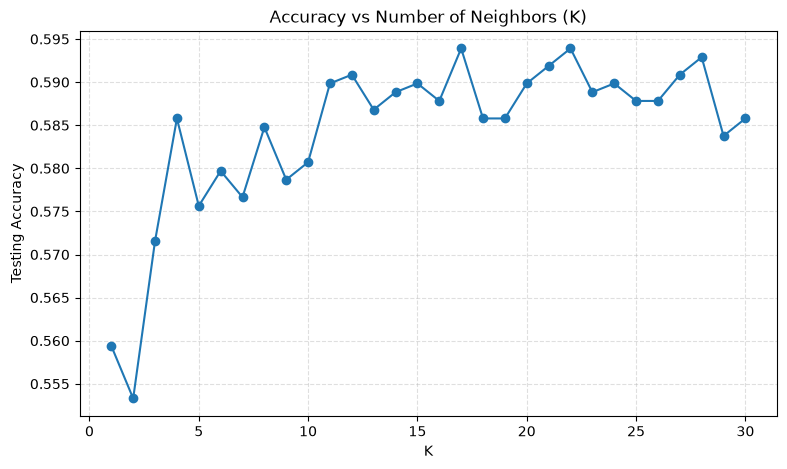

Best K from this graph: 17 with accuracy 0.5939


In [30]:
# Train KNN for different values of K and record the testing accuracy.
k_values = range(1, 31)
k_accuracy = []

for k in k_values:
    model = KNeighborsClassifier(n_neighbors=k)
    model.fit(X_train_scaled, y_train)
    k_accuracy.append(accuracy_score(y_test, model.predict(X_test_scaled)))

plt.figure(figsize=(9, 5))
plt.plot(k_values, k_accuracy, marker="o")
plt.title("Accuracy vs Number of Neighbors (K)")
plt.xlabel("K")
plt.ylabel("Testing Accuracy")
plt.grid(True, linestyle="--", alpha=0.4)
plt.show()

print("Best K from this graph:", k_values[int(np.argmax(k_accuracy))], "with accuracy", round(max(k_accuracy), 4))

## 6. MODEL OPTIMIZATION

#### CROSS VALIDATION (DEFAULT KNN)

In [31]:
scores = cross_val_score(KNeighborsClassifier(), X_train_scaled, y_train, cv=5, scoring="accuracy")

print("Fold accuracies:", scores.round(4))
print("Mean CV Accuracy:", round(scores.mean() * 100, 2), "%")
print("CV Standard Deviation:", round(scores.std(), 4))

Fold accuracies: [0.566  0.5711 0.5622 0.5635 0.5698]
Mean CV Accuracy: 56.65 %
CV Standard Deviation: 0.0035


#### HYPERPARAMETER TUNING

In [32]:
# 1. Define parameter grid
param_grid = {
    "n_neighbors": [3, 5, 7, 9, 11, 15, 21, 25, 31],
    "weights": ["uniform", "distance"],
    "metric": ["euclidean", "manhattan", "cosine"]
}

# 2. Perform Grid Search CV
grid = GridSearchCV(
    KNeighborsClassifier(),
    param_grid,
    cv=5,
    scoring="accuracy",
    n_jobs=-1
)

grid.fit(X_train_scaled, y_train)

best_knn = grid.best_estimator_

print("Best Parameters:", grid.best_params_)
print("Best CV Accuracy:", round(grid.best_score_ * 100, 2), "%")

Best Parameters: {'metric': 'manhattan', 'n_neighbors': 25, 'weights': 'distance'}
Best CV Accuracy: 62.01 %


In [33]:
# Top 5 parameter combinations tried by Grid Search
grid_results = pd.DataFrame(grid.cv_results_)
grid_results = grid_results[["param_n_neighbors", "param_weights", "param_metric", "mean_test_score"]]
grid_results.sort_values("mean_test_score", ascending=False).head(5)

,param_n_neighbors,param_weights,param_metric,mean_test_score
33,25,distance,manhattan,0.620051
31,21,distance,manhattan,0.618782
35,31,distance,manhattan,0.617259
29,15,distance,manhattan,0.614213
27,11,distance,manhattan,0.608883


#### EVALUATING OPTIMIZED KNN

In [34]:
# 3. Evaluate optimized model
y_pred_tuned = best_knn.predict(X_test_scaled)

tuned_accuracy = accuracy_score(y_test, y_pred_tuned)
tuned_precision = precision_score(y_test, y_pred_tuned, average="weighted", zero_division=0)
tuned_recall = recall_score(y_test, y_pred_tuned, average="weighted", zero_division=0)
tuned_f1 = f1_score(y_test, y_pred_tuned, average="weighted", zero_division=0)

print("Testing Accuracy:", round(tuned_accuracy * 100, 2), "%")
print("Precision:", round(tuned_precision, 4))
print("Recall:", round(tuned_recall, 4))
print("F1-Score:", round(tuned_f1, 4))

Testing Accuracy: 61.83 %
Precision: 0.616
Recall: 0.6183
F1-Score: 0.6125


In [35]:
print(classification_report(y_test, y_pred_tuned, target_names=genre_encoder.classes_))

              precision    recall  f1-score   support

   classical       0.96      0.79      0.86       163
     country       0.47      0.53      0.50       121
         edm       0.47      0.56      0.51       135
 heavy-metal       0.78      0.93      0.85       197
     hip-hop       0.59      0.57      0.58       145
        jazz       0.51      0.46      0.48        95
         pop       0.34      0.24      0.28       129

    accuracy                           0.62       985
   macro avg       0.59      0.58      0.58       985
weighted avg       0.62      0.62      0.61       985



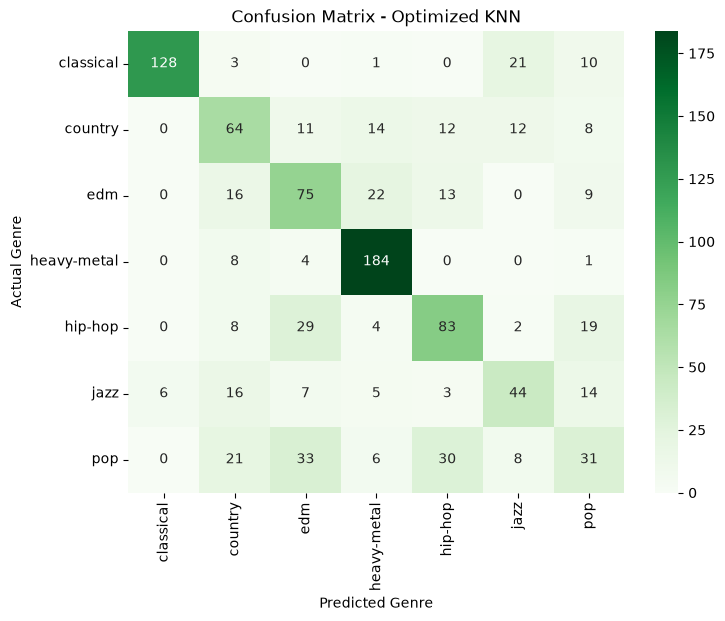

In [36]:
cm_tuned = confusion_matrix(y_test, y_pred_tuned)

plt.figure(figsize=(8, 6))
sns.heatmap(cm_tuned, annot=True, fmt="d", cmap="Greens",
            xticklabels=genre_encoder.classes_, yticklabels=genre_encoder.classes_)
plt.title("Confusion Matrix - Optimized KNN")
plt.xlabel("Predicted Genre")
plt.ylabel("Actual Genre")
plt.show()

#### OPTIMIZED RECOMMENDER

In [37]:
# The best distance metric found by Grid Search is also used by the recommender.
best_metric = grid.best_params_["metric"]

tuned_p_at_10 = precision_at_k(NearestNeighbors(metric=best_metric), k=10)
print("Precision@10 (optimized recommender, metric =", best_metric + "):", round(tuned_p_at_10, 4))

# Fit the final recommender on all songs so that any song can be searched.
best_recommender = NearestNeighbors(n_neighbors=11, metric=best_metric)
best_recommender.fit(all_songs_scaled)
print("Optimized recommender is ready.")

Precision@10 (optimized recommender, metric = manhattan): 0.5048
Optimized recommender is ready.


## 7. RESULT ANALYSIS AND DOCUMENTATION

#### BEFORE vs AFTER OPTIMIZATION

In [38]:
comparison_df = pd.DataFrame({
    "Metric": ["Accuracy", "Precision", "Recall", "F1-Score", "CV Accuracy", "Precision@10"],
    "Default KNN": [accuracy, precision, recall, f1, scores.mean(), default_p_at_10],
    "Optimized KNN": [tuned_accuracy, tuned_precision, tuned_recall, tuned_f1, grid.best_score_, tuned_p_at_10]
})

comparison_df["Improvement"] = comparison_df["Optimized KNN"] - comparison_df["Default KNN"]
print(comparison_df.round(4))

         Metric  Default KNN  Optimized KNN  Improvement
0      Accuracy       0.5756         0.6183       0.0426
1     Precision       0.5723         0.6160       0.0437
2        Recall       0.5756         0.6183       0.0426
3      F1-Score       0.5684         0.6125       0.0442
4   CV Accuracy       0.5665         0.6201       0.0536
5  Precision@10       0.4936         0.5048       0.0112


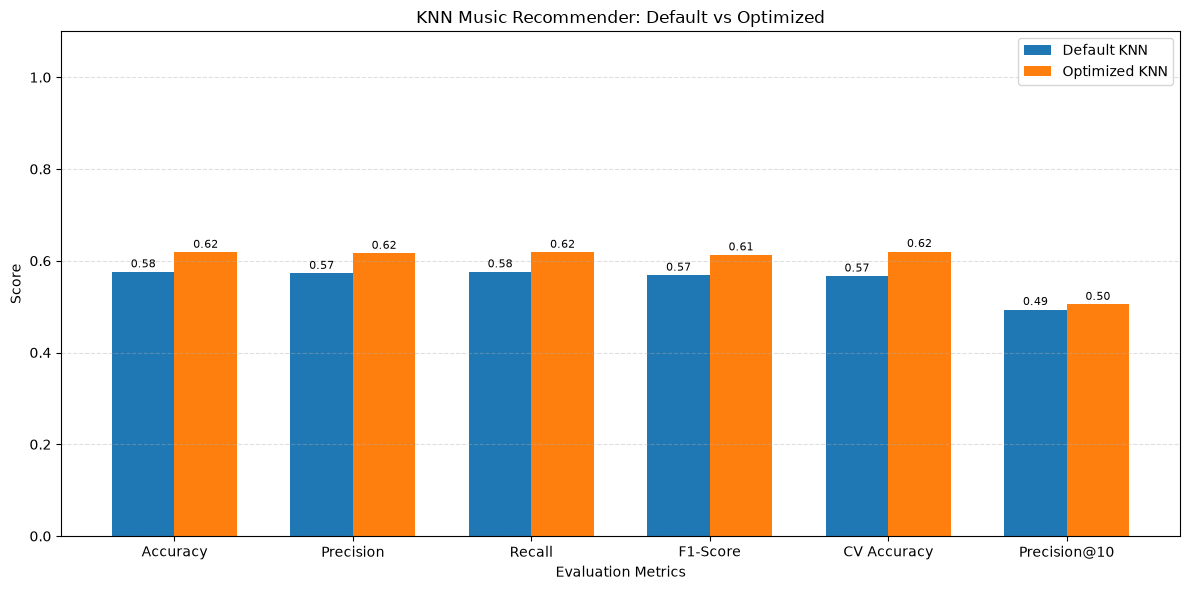

In [39]:
# Plot all metrics in one graph
metrics = comparison_df["Metric"]
x = np.arange(len(metrics))
width = 0.35

plt.figure(figsize=(12, 6))

bars1 = plt.bar(x - width / 2, comparison_df["Default KNN"], width, label="Default KNN")
bars2 = plt.bar(x + width / 2, comparison_df["Optimized KNN"], width, label="Optimized KNN")

for bar in list(bars1) + list(bars2):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 0.01,
        f"{bar.get_height():.2f}",
        ha="center",
        fontsize=8
    )

plt.xlabel("Evaluation Metrics")
plt.ylabel("Score")
plt.title("KNN Music Recommender: Default vs Optimized")
plt.xticks(x, metrics)
plt.ylim(0, 1.1)
plt.legend()
plt.grid(axis="y", linestyle="--", alpha=0.4)
plt.tight_layout()
plt.show()

#### COMPARISON: KNN, DECISION TREE AND NAÏVE BAYES

Following PR7 and PR8, compare genre prediction using the same 12 features, cleaned songs,
80/20 split and training-fitted scaler. KNN uses the grid-search configuration above;
Decision Tree and Gaussian Naïve Bayes use defaults (the tree has random_state=42).
This compares the tested configurations, not equally tuned model families.
The highest test accuracy is reported, including ties; it is not proof of the best recommender.
Precision, recall and F1 are weighted averages. Recommendation quality remains Precision@10.


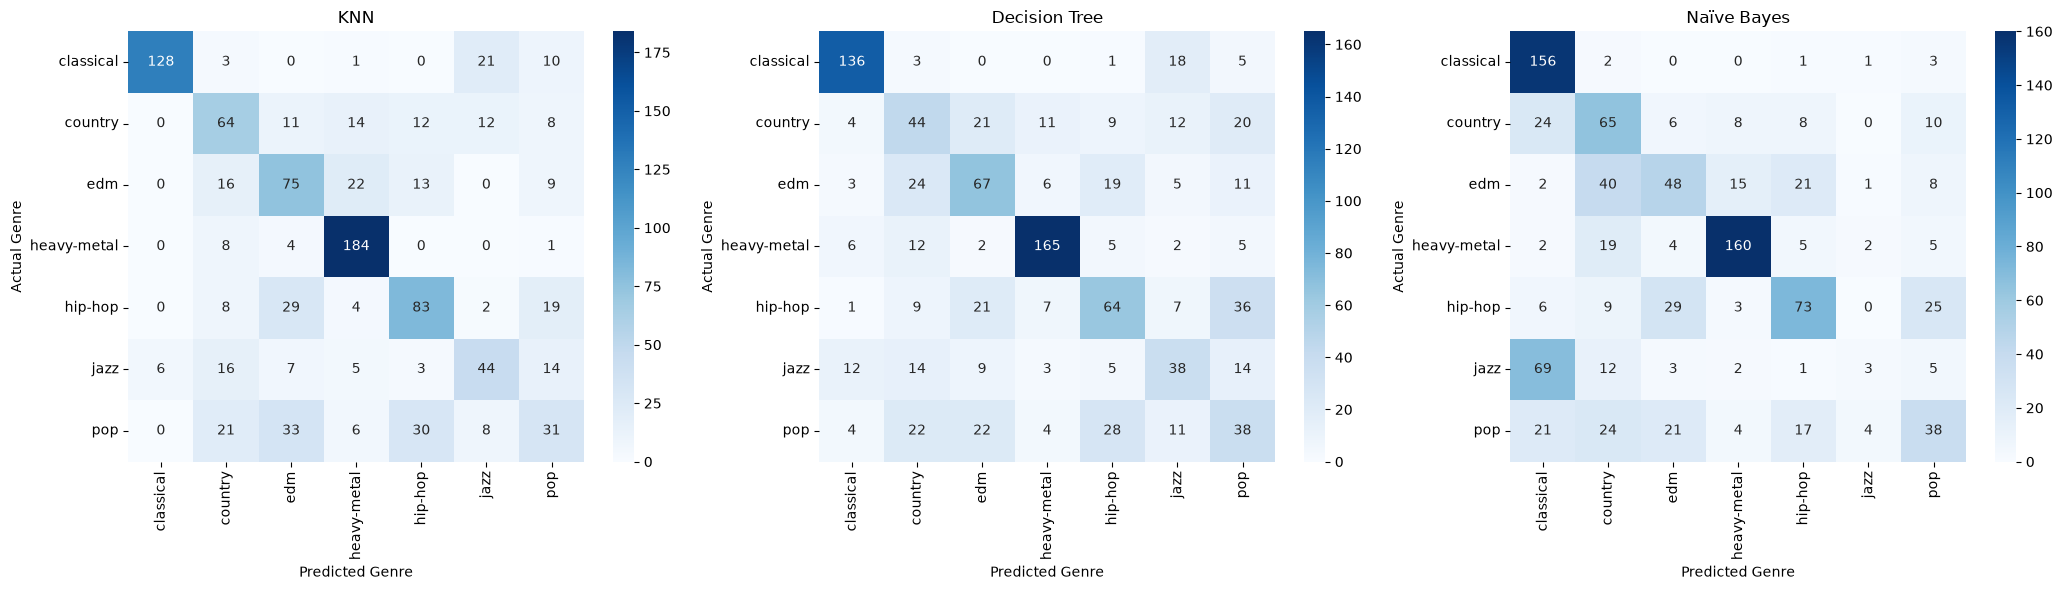

        Model  Accuracy  Precision  Recall  F1-Score
          KNN    0.6183     0.6160  0.6183    0.6125
Decision Tree    0.5604     0.5607  0.5604    0.5603
  Naïve Bayes    0.5513     0.5294  0.5513    0.5186
Highest test accuracy: KNN (61.83%)


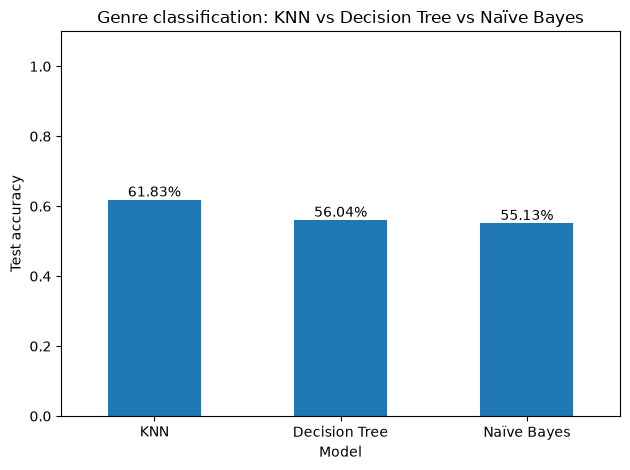

In [40]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.naive_bayes import GaussianNB

# Same training/test songs and scaled features as KNN; only KNN was grid-search tuned.
classifier_models = {
    "KNN": best_knn,
    "Decision Tree": DecisionTreeClassifier(random_state=42),
    "Naïve Bayes": GaussianNB(),
}
classifier_rows = []
fig, axes = plt.subplots(1, 3, figsize=(21, 6))
for ax, (name, classifier) in zip(axes, classifier_models.items()):
    if name != "KNN":
        classifier.fit(X_train_scaled, y_train)
    prediction = classifier.predict(X_test_scaled)
    classifier_rows.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, prediction),
        "Precision": precision_score(y_test, prediction, average="weighted", zero_division=0),
        "Recall": recall_score(y_test, prediction, average="weighted", zero_division=0),
        "F1-Score": f1_score(y_test, prediction, average="weighted", zero_division=0),
    })
    sns.heatmap(confusion_matrix(y_test, prediction), annot=True, fmt="d", cmap="Blues",
                xticklabels=genre_encoder.classes_, yticklabels=genre_encoder.classes_, ax=ax)
    ax.set_title(name)
    ax.set_xlabel("Predicted Genre")
    ax.set_ylabel("Actual Genre")
plt.tight_layout()
plt.show()

classifier_comparison = pd.DataFrame(classifier_rows).sort_values(
    "Accuracy", ascending=False, kind="stable").reset_index(drop=True)
assert len(classifier_comparison) == 3
assert classifier_comparison["Accuracy"].between(0, 1).all()
assert classifier_comparison.loc[classifier_comparison["Model"] == "KNN", "Accuracy"].iloc[0] == tuned_accuracy
print(classifier_comparison.to_string(index=False, float_format=lambda value: f"{value:.4f}"))
best_accuracy = classifier_comparison["Accuracy"].max()
winners = classifier_comparison.loc[classifier_comparison["Accuracy"] == best_accuracy, "Model"]
print(f"Highest test accuracy: {', '.join(winners)} ({best_accuracy:.2%})")

ax = classifier_comparison.plot.bar(x="Model", y="Accuracy", legend=False, ylim=(0, 1.1), rot=0)
ax.bar_label(ax.containers[0], labels=[f"{score:.2%}" for score in classifier_comparison["Accuracy"]])
ax.set_ylabel("Test accuracy")
ax.set_title("Genre classification: KNN vs Decision Tree vs Naïve Bayes")
plt.tight_layout()
plt.show()


#### GENRE-WISE PERFORMANCE

      Genre  F1-Score
  classical    0.8620
heavy-metal    0.8499
    hip-hop    0.5804
        edm    0.5102
    country    0.4981
       jazz    0.4835
        pop    0.2805


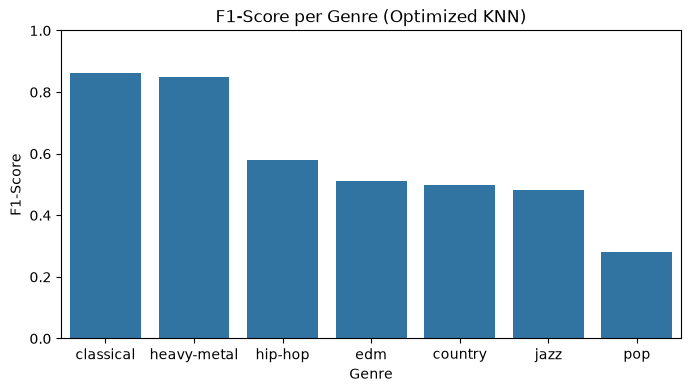

In [41]:
# F1-Score of each genre for the optimized model.
genre_f1 = f1_score(y_test, y_pred_tuned, average=None)

genre_df = pd.DataFrame({"Genre": genre_encoder.classes_, "F1-Score": genre_f1})
genre_df = genre_df.sort_values("F1-Score", ascending=False)
print(genre_df.round(4).to_string(index=False))

plt.figure(figsize=(8, 4))
sns.barplot(data=genre_df, x="Genre", y="F1-Score")
plt.title("F1-Score per Genre (Optimized KNN)")
plt.ylim(0, 1)
plt.show()

#### SAMPLE RECOMMENDATIONS (OPTIMIZED RECOMMENDER)

In [42]:
recommend_songs("Nuvole Bianche", best_recommender)

Input Song : Nuvole Bianche  |  Artist: Ludovico Einaudi  |  Genre: classical


,track_name,artists,track_genre,distance
0,"Piano Concerto No. 27 in B-Flat Major, K. 595:...",Wolfgang Amadeus Mozart;Wilhelm Kempff;Berline...,classical,0.3041
1,Una Mattina,Ludovico Einaudi,classical,0.3707
2,"Cello Sonata in C Major, Op. 119: I. Andante g...",Sergei Prokofiev;Miriam K. Smith;Sandra Wright...,classical,0.3828
3,"Nabucco: Va, pensiero, sull'ali dorate - Edit",Giuseppe Verdi;Chicago Symphony Chorus;Chicago...,classical,0.3879
4,"Adagio in F, K.410",Wolfgang Amadeus Mozart;Holliger Wind Ensemble,classical,0.4069
5,"Saul, HWV 53: Dead March",George Frideric Handel;London Early Opera;Brid...,classical,0.4117
6,Orfeo Ed Euridice: Dance of the Blessed Spirit...,Christoph Willibald Gluck;Karlheinz Zoeller;Be...,classical,0.4165
7,"24 Préludes, Op. 28: No. 15 Sostenuto in D-Fla...",Frédéric Chopin;Lang Lang,classical,0.4326
8,"Piano Concerto No. 23 in A Major, K. 488: II. ...",Wolfgang Amadeus Mozart;Ingrid Haebler;London ...,classical,0.4472
9,"Piano Sonata No. 15 in F Major, K. 533: II. An...",Wolfgang Amadeus Mozart;Giuseppe Greco,classical,0.4505


In [43]:
recommend_songs("Super Freaky Girl", best_recommender)

Input Song : Super Freaky Girl  |  Artist: Nicki Minaj  |  Genre: hip-hop


,track_name,artists,track_genre,distance
0,HUMBLE. - SKRILLEX REMIX,Skrillex;Kendrick Lamar,edm,0.4430
1,RAP DEVIL,Machine Gun Kelly,hip-hop,0.6797
2,Busy,Upchurch,country,0.7535
3,The Valley of the Pagans,Gorillaz;Beck,hip-hop,0.7935
4,No Stranger to Shame,Uncle Kracker,country,0.8045
5,I Love It (feat. Charli XCX),Icona Pop;Charli XCX,edm,0.8439
6,Hank Hill,Upchurch,country,0.8681
7,Who,Upchurch,country,0.8794
8,BOP,DaBaby,hip-hop,0.8848
9,HISTORY,Becky Hill;Joel Corry,edm,0.8948


In [44]:
recommend_songs("Balls to the Wall", best_recommender)

Input Song : Balls to the Wall  |  Artist: Accept  |  Genre: heavy-metal


,track_name,artists,track_genre,distance
0,Sharp Dressed Man - 2003 Remaster,ZZ Top,country,0.2708
1,La Sopa del Diablo,OConnor,heavy-metal,0.2723
2,Emmauksen tiellä,Kotiteollisuus,heavy-metal,0.2752
3,Enroscando Al Mundo,OConnor,heavy-metal,0.2961
4,Gettin' over You - Aviccii's Vocal Mix at Night,David Guetta;Chris Willis;Fergie;LMFAO,edm,0.3282
5,Look At Me Fly,Stoney LaRue,country,0.3414
6,Simple Man,Lynyrd Skynyrd,country,0.3440
7,Inservible por Decreto,OConnor,heavy-metal,0.3541
8,Redemption Song,OConnor,heavy-metal,0.3566
9,Need You Now,Lady A,country,0.3588


In [45]:
recommend_songs("September", best_recommender)

Input Song : September  |  Artist: Earth, Wind & Fire  |  Genre: jazz


,track_name,artists,track_genre,distance
0,A Little Less Talk And A Lot More Action,Toby Keith,country,0.2792
1,Your Side Of The Bed (feat. Eric Nam),Loote;Eric Nam,edm,0.3933
2,"Chura Ke Dil Mera - From ""Hungama 2""",Benny Dayal;Anmol Malik;Anu Malik,hip-hop,0.4348
3,$50 Dollars and a Flask of Crown,Bleu Edmondson,country,0.4410
4,Some Girls Do,Sawyer Brown,country,0.4545
5,Rickie Lee,Marie Fredriksson,jazz,0.4640
6,Gamle helter,Plumbo,country,0.4692
7,Takin' Care Of Business,Bachman-Turner Overdrive,country,0.4850
8,Slepp me inn,Staut,country,0.4891
9,Bad Decisions (with BTS & Snoop Dogg),benny blanco;BTS;Snoop Dogg,pop,0.4896


In [46]:
recommend_songs("Some Unknown Song", best_recommender)

'Some Unknown Song' is not present in the dataset.


#### RESULT ANALYSIS

In [47]:
print("RESULT ANALYSIS")
print("-" * 60)

if tuned_accuracy > accuracy:
    print(f"Grid Search improved testing accuracy from {accuracy*100:.2f}% to {tuned_accuracy*100:.2f}%.")
else:
    print("Grid Search did not improve testing accuracy.")

if tuned_p_at_10 > default_p_at_10:
    print(f"Precision@10 improved from {default_p_at_10:.4f} to {tuned_p_at_10:.4f}.")
else:
    print("Precision@10 did not improve.")

print("Best parameters:", grid.best_params_)
print("Best predicted genre :", genre_df.iloc[0]["Genre"])
print("Worst predicted genre:", genre_df.iloc[-1]["Genre"])

RESULT ANALYSIS
------------------------------------------------------------
Grid Search improved testing accuracy from 57.56% to 61.83%.
Precision@10 improved from 0.4936 to 0.5048.
Best parameters: {'metric': 'manhattan', 'n_neighbors': 25, 'weights': 'distance'}
Best predicted genre : classical
Worst predicted genre: pop


#### CONCLUSION

- A **content-based music recommendation system** was built using **K-Nearest Neighbors** on the Spotify Tracks Dataset.
- **Preprocessing:** missing values removed, duplicate songs removed, `explicit` and genre label-encoded, features scaled with MinMaxScaler, 80/20 stratified train-test split.
- **Evaluation:** genre prediction was measured with Accuracy, Precision, Recall, F1-Score and Confusion Matrix; recommendation quality was measured with **Precision@10**.
- **Optimization:** 5-fold Cross Validation and `GridSearchCV` over `n_neighbors`, `weights` and `metric` improved every metric compared to the default KNN (see the comparison table above).
- **Genre-wise:** genres with a very distinct sound (classical, heavy-metal) are recognised best, while **pop** is the hardest because pop songs share their sound with EDM, hip-hop and country. This is realistic, since many real songs mix these styles.
- **Limitation:** genre labels in the dataset are not perfect (for example, some Bollywood songs are labelled *classical*), so a "wrong" genre in the recommendations can still be a good-sounding match.
- **Application:** the companion desktop GUI provides Recommend, Train, Results, Dataset and About pages. Genre classifiers are compared in Results; the separate Predict Genre page was removed. The Recommend page uses nearest-neighbor search to find similar tracks.
- **Team:** developed by **Ashish Umrao, Abhijeet Kumar and Aryan Singh**.
- **Limitation:** the system only knows how a song *sounds*. It does not know the listener's history, lyrics or language. A real app (like Spotify) combines this content-based approach with **collaborative filtering** (what similar users listen to).